# 06｜把参数、数据和训练循环接起来

上一课已经能更新两个数。现在让同一个模型看完40组 $y=2x+1$ 数据，
一次读取8组，看一批就更新一次，最终把整条直线学出来。
w、b 必须在这些更新之间保留下来，输入和目标必须始终配成同一份样本。

这会用到三个对象：模型保管参数并做预测，数据集按编号返回样本，
训练循环把一批数据的误差变成一次更新。下面围绕这条直线把它们接起来。

In [1]:
from support import ROOT, check, show, style

## 1. class 把状态与操作放到一起


    模型每处理一批新输入，都要使用当前的 w、b。把它们存在 `self.w`、`self.b` 中，
    就能由同一个对象持续保管；`self` 指向当前这一份模型。
    `__init__` 建立这份状态，`forward` 描述拿到输入后怎样得到预测。

    `ScalarLine(nn.Module)` 继承 PyTorch 的模型接口。
    `super().__init__()` 初始化父类维护的参数记录，随后赋给属性的 `nn.Parameter`
    就能被登记。调用 `model(x)` 时，PyTorch 会执行这份模型的 `forward(x)`。

In [2]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1); torch.manual_seed(6); style()
class ScalarLine(nn.Module):
    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.tensor(0.))
        self.b = nn.Parameter(torch.tensor(0.))
    def forward(self, x):
        return self.w * x + self.b

## 2. 哪些数会交给优化器


    一个模型属性可以存很多数，优化器需要知道其中哪些要学习。
    `nn.Parameter` 让 w、b 出现在 `model.parameters()` 中；优化器稍后接收的正是这份列表。
    单纯给对象加一个 Tensor 属性，不会把它加入可学习参数列表。

    下格特意放入 `note` 和 buffer `scale`，对照两种输出：参数名单只有 w、b，
    `state_dict()` 还保存 scale。buffer 适合随模型保存、迁移的固定状态。
    这里的 forward 只读取 w、b，初值都是0，因此两个输入对应的预测也都是0。

In [3]:
model = ScalarLine()
model.note = torch.tensor(7.)
model.register_buffer('scale', torch.tensor(1.))
print('可学习参数:', [(name, tuple(p.shape)) for name, p in model.named_parameters()])
print('保存的状态:', list(model.state_dict()))
print('模型输出:', model(torch.tensor([1., 2.])))

可学习参数: [('w', ()), ('b', ())]
保存的状态: ['w', 'b', 'scale']
模型输出: tensor([0., 0.], grad_fn=<AddBackward0>)


### 练习 6.1：判断参数登记

写一个仅含可学习标量 `gain=2` 和普通 Tensor `offset=1` 的模块，返回可学习参数总元素数。

In [4]:
ex_t61_result = None

In [5]:
# 填写上一格后，运行检查。
check('登记的参数元素数', ex_t61_result, 1)

待填写：登记的参数元素数


<details>
<summary>提示</summary>

继承 `nn.Module`，初始化父类，然后只给 `gain` 包装 `nn.Parameter`。

</details>

<details>
<summary>参考答案</summary>

```python
class ExT61Model(nn.Module):
    def __init__(self):
        super().__init__()
        self.gain = nn.Parameter(torch.tensor(2.))
        self.offset = torch.tensor(1.)
ex_t61_result = sum(p.numel() for p in ExT61Model().parameters())
```

</details>

## 3. Dataset：输入与目标按编号配对


    对直线数据，输入2的目标应该是5。只要读错配对关系，模型就会学另一件事。
    `Dataset` 将取样过程放在 `__getitem__` 中：同一个 index 同时取 x 和 y。
    Python 的 `dataset[2]` 会调用这个方法，`len(dataset)` 会调用 `__len__`。

    `LineDataset` 只保存已有 Tensor，并按行返回。下面建立8份样本，
    打印编号2时应看到 `(tensor([2.]), tensor([5.]))`。

In [6]:
from torch.utils.data import Dataset, DataLoader
class LineDataset(Dataset):
    def __init__(self, x, y):
        self.x, self.y = x, y
    def __len__(self):
        return len(self.x)
    def __getitem__(self, index):
        return self.x[index], self.y[index]
x_data = torch.arange(8, dtype=torch.float32).reshape(-1, 1)
dataset = LineDataset(x_data, 2 * x_data + 1)
print('总数:', len(dataset), '编号2:', dataset[2])

总数: 8 编号2: (tensor([2.]), tensor([5.]))


## 4. DataLoader：四个样本成为一批


    一次处理四份输入，可以把四次预测合为一次张量运算。
    DataLoader 从 Dataset 取出样本，将四个 `(1,)` 输入堆成 `(4,1)`，目标也排成 `(4,1)`。
    `iter(loader)` 建立迭代器，`next(...)` 就取出当前的下一批。

    `shuffle=True` 改变每轮的取样顺序，固定生成器种子可复现这次顺序。
    打印出的输入虽然经过打乱，每一列对应的目标仍满足 $y=2x+1$。
    `num_workers=0` 表示由当前进程读取这组小数据。

In [7]:
loader = DataLoader(dataset, batch_size=4, shuffle=True,
                    generator=torch.Generator().manual_seed(6), num_workers=0)
batch_x, batch_y = next(iter(loader))
print('输入:', batch_x.T, '目标:', batch_y.T)
print('batch形状:', tuple(batch_x.shape), tuple(batch_y.shape))
print('逐个样本编号:', list(range(len(dataset))))

输入: tensor([[3., 5., 6., 1.]]) 目标: tensor([[ 7., 11., 13.,  3.]])
batch形状: (4, 1) (4, 1)
逐个样本编号: [0, 1, 2, 3, 4, 5, 6, 7]


### 练习 6.2：最后一批有几个样本

把 10 个样本装入 batch_size=4、shuffle=False 的 DataLoader，返回每批样本数。

In [8]:
ex_t62_result = None

In [9]:
# 填写上一格后，运行检查。
check('三批的大小', ex_t62_result, [4, 4, 2])

待填写：三批的大小


<details>
<summary>提示</summary>

`len(batch)` 读出这一批的第一维；默认保留最后不足一批的数据。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t62_data = torch.arange(10)
ex_t62_loader = DataLoader(ex_t62_data, batch_size=4, shuffle=False)
ex_t62_result = [len(batch) for batch in ex_t62_loader]
```

</details>

## 5. nn.Linear 的行列约定


    已经有了一批输入，预测仍然是乘权重、加偏置。`nn.Linear` 将这组运算和参数封装在一起。
    输入 `X` 为 $(B,D_{in})$，`nn.Linear(Din,Dout)` 的 `weight` 为
    $(D_{out},D_{in})$，`bias` 为 $(D_{out},)$。它计算
    $$\hat Y=XW^\top+b\quad\in\mathbb R^{B\times D_{out}}.$$
    本例 $D_{in}=D_{out}=1$。把权重设为2、偏置设为1，预测就应逐项等于 batch_y。
    输出与目标都为 `(B,1)`，相减时每个位置对应同一份样本。

In [10]:
affine = nn.Linear(1, 1)
with torch.no_grad():
    affine.weight.fill_(2.)
    affine.bias.fill_(1.)
direct = batch_x @ affine.weight.T + affine.bias
print('W,b:', affine.weight.shape, affine.bias.shape)
print('预测与目标:', affine(batch_x).shape, batch_y.shape)
check('Linear等于矩阵运算', affine(batch_x), direct)

W,b: torch.Size([1, 1]) torch.Size([1])
预测与目标: torch.Size([4, 1]) torch.Size([4, 1])
通过：Linear等于矩阵运算


## 6. 同一起点比较手动 SGD 与优化器


    优化器即将替代手写的 `parameter -= lr * parameter.grad`。
    用两份从相同参数出发的模型，各走一步，就能检查它实际做了什么。
    两次 `nn.Linear` 会各自抽取随机初值，`load_state_dict` 将第二份参数改成第一份的数值。

    两边共同使用输入 `[1,2]`、目标 `[3,5]` 和学习率0.1。
    `nn.MSELoss()` 对应 $L=B^{-1}\sum_i(\hat y_i-y_i)^2$；残差对预测求导时得到 $2e_i/B$。

In [11]:
manual = nn.Linear(1, 1)
automatic = nn.Linear(1, 1)
automatic.load_state_dict(manual.state_dict())
step_x = torch.tensor([[1.], [2.]])
step_y = torch.tensor([[3.], [5.]])
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(automatic.parameters(), lr=0.1)
print('相同起点:', manual.state_dict(), automatic.state_dict())

相同起点: OrderedDict({'weight': tensor([[0.9737]]), 'bias': tensor([0.2161])}) OrderedDict({'weight': tensor([[0.9737]]), 'bias': tensor([0.2161])})


### 练习 6.3：自己完成矩阵正向

输入 $(2,2)$、权重 $(1,2)$、偏置 $(1,)$，按 $XW^\top+b$ 计算。

In [12]:
ex_t63_X = torch.tensor([[1., 2.], [3., 4.]])
ex_t63_W = torch.tensor([[2., -1.]])
ex_t63_b = torch.tensor([0.5])
ex_t63_result = None

In [13]:
# 填写上一格后，运行检查。
check('矩阵正向', ex_t63_result, [[0.5], [2.5]])

待填写：矩阵正向


<details>
<summary>提示</summary>

`W.T` 先把输出优先的权重矩阵转置。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t63_X = torch.tensor([[1., 2.], [3., 4.]])
ex_t63_W = torch.tensor([[2., -1.]])
ex_t63_b = torch.tensor([0.5])
ex_t63_result = ex_t63_X @ ex_t63_W.T + ex_t63_b
```

</details>

## 7. 看优化器能否复现手写的一步


    第一份模型清除旧梯度、计算损失并反传，随后逐个修改参数。
    第二份模型经历同样的正向和反向计算，由 `optimizer.step()` 读取 `.grad` 并更新。
    最后两项检查分别比较 weight、bias，二者都应相等。

    `zero_grad` 准备这一批的梯度收集位置，`backward` 填入梯度，`step` 使用它们。
    这三个调用对应的是三个不同动作，后面的多批训练只会重复这段过程。

In [14]:
manual.zero_grad(set_to_none=True)
manual_loss = loss_fn(manual(step_x), step_y)
manual_loss.backward()
with torch.no_grad():
    for parameter in manual.parameters():
        parameter -= 0.1 * parameter.grad
optimizer.zero_grad(set_to_none=True)
loss_fn(automatic(step_x), step_y).backward()
optimizer.step()
for name, parameter in manual.named_parameters():
    check('SGD一致：' + name, parameter, automatic.state_dict()[name])

通过：SGD一致：weight
通过：SGD一致：bias


## 8. train、eval 与 no_grad 分别控制什么


    预测新样本时，通常只需要数值。下格把模型切到 `eval()` 后，输出的
    `requires_grad` 仍为 True；进入 `torch.no_grad()` 后，同一预测才不再记录求导过程。

    `.train()` 与 `.eval()` 切换模块运行模式，Dropout、BatchNorm 会据此改变行为，
    本例的 Linear 在两种模式下使用同一公式。`no_grad()` 控制这次运算是否记录梯度，
    所以评估循环会同时使用 `eval()` 和 `no_grad()`。

In [15]:
automatic.eval()
prediction_with_graph = automatic(step_x)
with torch.no_grad():
    prediction_without_graph = automatic(step_x)
print('eval仍求导:', prediction_with_graph.requires_grad)
print('no_grad:', prediction_without_graph.requires_grad)
print('模型training标记:', automatic.training)
automatic.train()

eval仍求导: True
no_grad: False
模型training标记: False


Linear(in_features=1, out_features=1, bias=True)

### 练习 6.4：MSE 的批平均梯度

预测 `[1,2]`，目标 `[3,3]`。用 `nn.MSELoss` 反传，返回预测的梯度。

In [16]:
ex_t64_result = None

In [17]:
# 填写上一格后，运行检查。
check('MSE预测梯度', ex_t64_result, [-2., -1.])

待填写：MSE预测梯度


<details>
<summary>提示</summary>

对两个元素平均：每项导数是 $2(\hat y_i-y_i)/2$。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t64_pred = torch.tensor([1., 2.], requires_grad=True)
nn.MSELoss()(ex_t64_pred, torch.tensor([3., 3.])).backward()
ex_t64_result = ex_t64_pred.grad.clone()
```

</details>

## 9. 逐批训练，逐轮记录


    一步更新已经核对过，现在把它放回本章的40组数据中。
    输入均匀分布在 $[-1,1]$，目标为 $y=2x+1$；每批8个样本，一轮需要5次更新。
    完整遍历一遍训练集称为一轮 epoch。

    下面建立数据读取器、模型和优化器。它们都放在训练循环外：
    这样下一批读到新样本时，模型仍保存上一批刚学到的参数。

In [18]:
train_x = torch.linspace(-1, 1, 40).reshape(-1, 1)
train_y = 2 * train_x + 1
train_loader = DataLoader(LineDataset(train_x, train_y), batch_size=8,
                          shuffle=True, generator=torch.Generator().manual_seed(6))
trained = nn.Linear(1, 1)
train_optimizer = torch.optim.SGD(trained.parameters(), lr=0.1)
history = []

## 10. 一份可以从头重写的完整循环


    `for inputs, targets in train_loader` 每次取得一批配对数据；
    预测与目标都为 `(B,1)`，相减、平方、平均后得到一个标量损失。
    `loss.backward()` 从这个标量反传，随后优化器更新现有模型。

    `loss.item()` 只取数值来记账，反传仍使用 loss Tensor。
    整轮记账时乘 `len(inputs)`，将批均值还原成这一批的损失和，最后除以数据集总数。
    即使末批不足8个样本，每个样本也会获得相同权重。

In [19]:
for epoch in range(40):
    trained.train()
    total_loss = 0.
    for inputs, targets in train_loader:
        train_optimizer.zero_grad(set_to_none=True)
        predictions = trained(inputs)
        loss = loss_fn(predictions, targets)
        loss.backward()
        train_optimizer.step()
        total_loss += loss.item() * len(inputs)
    history.append(total_loss / len(train_loader.dataset))
print('学习结果:', trained.weight.item(), trained.bias.item(), '末轮MSE:', history[-1])

学习结果: 1.9999994039535522 0.9999999403953552 末轮MSE: 1.899813639738568e-13


输出中的两个参数应分别接近2和1。它们与末轮 MSE 一起说明：这份持续更新的模型已经从各批数据中恢复了同一条直线。

### 练习 6.5：不等大小 batch 的损失

两个 batch 分别有 4、2 个样本，批平均损失分别是 1、4，返回整组样本的平均损失。

In [20]:
ex_t65_result = None

In [21]:
# 填写上一格后，运行检查。
check('整轮加权平均', ex_t65_result, 2.)

待填写：整轮加权平均


<details>
<summary>提示</summary>

每批均值乘这一批样本数，合计后除以 6。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t65_result = (4 * 1. + 2 * 4.) / 6
```

</details>

## 11. 评估与画图


    左图是每轮训练损失，右图把最终预测与40个目标点画到同一坐标中。
    参数接近2、1时，预测线应该穿过这些点；如果损失下降而图中配对错乱，
    就要回到输入、目标的行号检查。这里的评估使用刚才那一份 trained 模型，
    参数会从训练阶段一直保留到画图阶段。

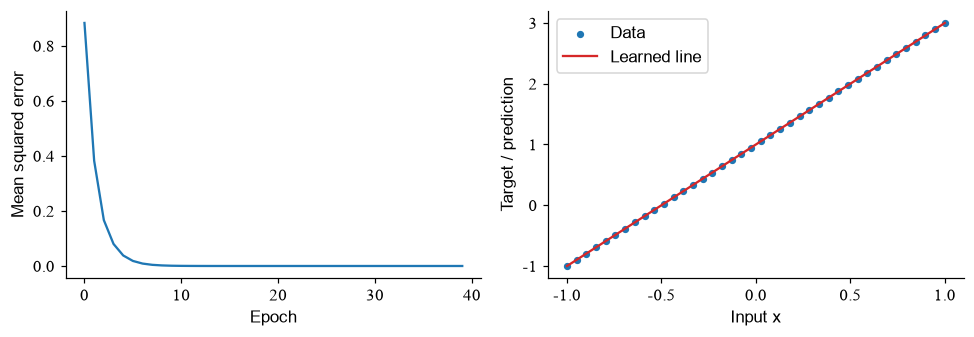

In [22]:
trained.eval()
with torch.no_grad():
    fitted = trained(train_x)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(history); axes[0].set(xlabel='Epoch', ylabel='Mean squared error')
axes[1].scatter(train_x[:, 0], train_y[:, 0], s=14, label='Data')
axes[1].plot(train_x[:, 0], fitted[:, 0], color='tab:red', label='Learned line')
axes[1].set(xlabel='Input x', ylabel='Target / prediction'); axes[1].legend()
fig.tight_layout(); show(fig)

### 练习 6.6：验证 eval 与求导记录

建立 `nn.Linear(1,1)`，调用 `eval()`，在 `no_grad` 中预测。返回 `[model.training, output.requires_grad]`。

In [23]:
ex_t66_result = None

In [24]:
# 填写上一格后，运行检查。
check('评估模式与记录状态', ex_t66_result, [False, False])

待填写：评估模式与记录状态


<details>
<summary>提示</summary>

这两个布尔值分别表示模块模式和这次输出是否记录求导。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t66_model = nn.Linear(1, 1)
ex_t66_model.eval()
with torch.no_grad():
    ex_t66_output = ex_t66_model(torch.ones(2, 1))
ex_t66_result = [ex_t66_model.training, ex_t66_output.requires_grad]
```

</details>

## 带着问题读原文

[PyTorch：优化模型参数（官方源码）](https://github.com/pytorch/tutorials/blob/main/beginner_source/basics/optimization_tutorial.py)

找到训练函数的 `zero_grad`、`backward`、`step`，并追踪评估函数的 `no_grad`。指出评估集的样本在哪一行进入模型、是否会更新参数。

**单变量实验：**只把 batch_size 从 8 改成 40，保留 epoch 数与学习率。比较更新次数及损失曲线。